# K-means comparison of RFM customer segments

This notebook compares the rule-based RFM segmentation with a small K-means clustering extension using recency, frequency and monetary value.

In [1]:
import pandas as pd

rfm = pd.read_csv("../data/processed/rfm.csv")

rfm.head()

,customer_id,recency,frequency,monetary
0,fe51c153-fbec-4b64-9b00-2530035ef0e1_5c9d412f-...,3,29,302.33
1,fe51c153-fbec-4b64-9b00-2530035ef0e1_1f87fa27-...,61,6,8871.02
2,fe51c153-fbec-4b64-9b00-2530035ef0e1_7d44418a-...,3,13,1361.46
3,fe51c153-fbec-4b64-9b00-2530035ef0e1_bcaa9ba5-...,6,7,2167.98
4,fe51c153-fbec-4b64-9b00-2530035ef0e1_8c8ba83b-...,5,17,3356.54


In [2]:
rfm[["recency", "frequency", "monetary"]].describe()

,recency,frequency,monetary
count,5473.000000,5473.000000,5473.000000
mean,18.675132,14.285766,6528.695677
std,21.011694,9.052530,5569.833444
min,0.000000,1.000000,10.910000
25%,5.000000,8.000000,2666.190000
50%,10.000000,12.000000,5507.540000
75%,25.000000,17.000000,8967.170000
max,177.000000,67.000000,69452.920000


In [3]:
rfm[["recency", "frequency", "monetary"]].skew()

recency      2.698365
frequency    1.438284
monetary     2.359754
dtype: float64

In [4]:
import numpy as np

rfm_model = rfm.copy()

rfm_model["recency"] = np.log1p(rfm_model["recency"])
rfm_model["frequency"] = np.log1p(rfm_model["frequency"])
rfm_model["monetary"] = np.log1p(rfm_model["monetary"])

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_model[["recency", "frequency", "monetary"]]
)

In [6]:
rfm_model[["recency", "frequency", "monetary"]].skew()

recency     -0.135340
frequency   -0.288807
monetary    -1.104449
dtype: float64

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    results.append({
        "k": k,
        "inertia": kmeans.inertia_,
        "silhouette_score": silhouette_score(rfm_scaled, labels)
    })

results_df = pd.DataFrame(results)
results_df

,k,inertia,silhouette_score
0,2,10991.834367,0.299126
1,3,8258.556956,0.338325
2,4,6270.789257,0.322247
3,5,5266.197969,0.291524
4,6,4562.496368,0.300295


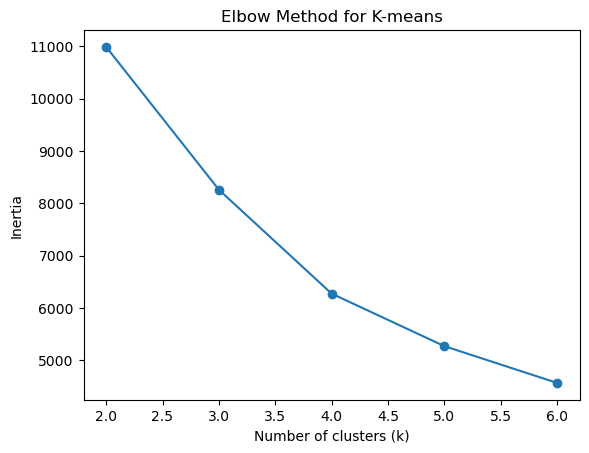

In [8]:
import matplotlib.pyplot as plt

plt.plot(results_df["k"], results_df["inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-means")
plt.show()

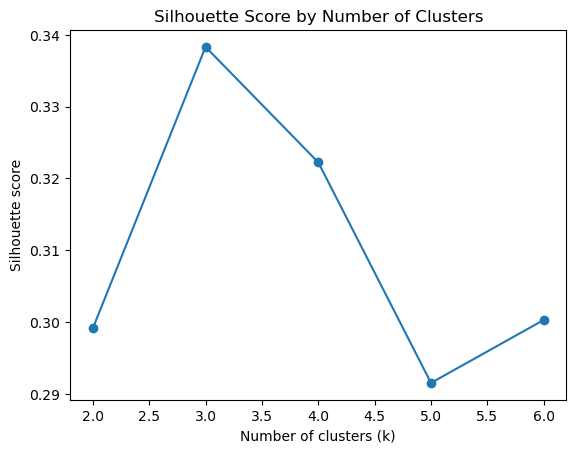

In [9]:
plt.plot(results_df["k"], results_df["silhouette_score"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score by Number of Clusters")
plt.show()

## Selecting the number of clusters

K-means was tested for k = 2–6. Three clusters were selected because k = 3 produced the highest silhouette score while retaining a simple, interpretable customer segmentation.

In [10]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm["cluster"] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,customer_id,recency,frequency,monetary,cluster
0,fe51c153-fbec-4b64-9b00-2530035ef0e1_5c9d412f-...,3,29,302.33,1
1,fe51c153-fbec-4b64-9b00-2530035ef0e1_1f87fa27-...,61,6,8871.02,0
2,fe51c153-fbec-4b64-9b00-2530035ef0e1_7d44418a-...,3,13,1361.46,1
3,fe51c153-fbec-4b64-9b00-2530035ef0e1_bcaa9ba5-...,6,7,2167.98,0
4,fe51c153-fbec-4b64-9b00-2530035ef0e1_8c8ba83b-...,5,17,3356.54,2


In [11]:
rfm["cluster"].value_counts().sort_index()

cluster
0    1895
1     495
2    3083
Name: count, dtype: int64

In [12]:
cluster_profile = (
    rfm.groupby("cluster")
    .agg(
        customer_count=("customer_id", "count"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean")
    )
    .round(2)
)

cluster_profile

,customer_count,avg_recency,avg_frequency,avg_monetary
cluster,,,,
0,1895,36.45,7.22,4131.67
1,495,4.49,30.22,741.48
2,3083,10.02,16.07,8931.24


In [14]:
cluster_medians = (
    rfm.groupby("cluster")
    .agg(
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median")
    )
    .round(2)
)

cluster_medians

,median_recency,median_frequency,median_monetary
cluster,,,
0,26.0,7.0,3432.18
1,3.0,32.0,505.23
2,10.0,14.0,7708.80


In [15]:
rfm_rules = pd.read_csv("../data/processed/rfm_segments.csv")

comparison = rfm.merge(
    rfm_rules,
    on="customer_id",
    how="left"
)

pd.crosstab(
    comparison["cluster"],
    comparison["segment"]
)

segment,General Development User,General Re-arrangement User,General Retention User,General Value User,Key Development User,Key Re-arrangement User,Key Retention User,Key Value User
cluster,,,,,,,,
0,351,13,1167,0,27,2,335,0
1,53,7,0,435,0,0,0,0
2,681,72,35,413,645,194,194,849


In [16]:
pd.crosstab(
    comparison["cluster"],
    comparison["segment"],
    normalize="index"
).round(3)

segment,General Development User,General Re-arrangement User,General Retention User,General Value User,Key Development User,Key Re-arrangement User,Key Retention User,Key Value User
cluster,,,,,,,,
0,0.185,0.007,0.616,0.000,0.014,0.001,0.177,0.000
1,0.107,0.014,0.000,0.879,0.000,0.000,0.000,0.000
2,0.221,0.023,0.011,0.134,0.209,0.063,0.063,0.275


## Conclusion

K-means produced three broader behavioural clusters. The most distinctive was a recent, high-frequency, low-spend cluster, 87.9% of whose customers were classified as General Value Users under the rule-based RFM approach. This shows that a similar target pattern appears under an alternative segmentation method.